# 컨텍스트 로트

**이 노트북에서 할 일**

1. 근거 문장의 자리와 무관한 문장 수만 바꾼 입력 9개를 만들고, 모두 입력 한도 안인지 확인합니다.
2. 사용자 메시지 하나로 넣은 입력으로 답을 받아 정답 코드가 있는지 세고, 한 번 더 실행해 비교합니다.
3. 04절의 시스템 지시를 넣어 같은 9개 조건을 다시 실행하고, 결과를 어디까지 말할 수 있는지 판단합니다.

**준비물** — API 키는 필요 없습니다. 인터넷 서비스의 모델을 부르지 않고, 내 컴퓨터에서 작은 언어 모델을 실행합니다.
그래서 비용은 들지 않습니다. 모델이 답을 만드는 계산은 모두 27번 합니다.

실행 시간은 2분 안팎입니다. 모델 파일은 03·04절과 같은 약 1GB(954MiB)이고, 캐시에 없으면 Hugging Face 사이트에서 내려받습니다.
노트북과 같은 계산을 스크립트로 실행했을 때 Python이 쓴 메모리는 최대 약 3.2GB였습니다.

**기준 버전** — 실습 폴더에 고정한 transformers 4.56.2와 torch 2.8.0을 씁니다.
모델은 `Qwen/Qwen2.5-0.5B-Instruct`이고, 판 번호(revision)를 `7ae557604adf67be50417f59c2c2f167def9a775`로 고정해 받습니다.

교재 출력은 Linux의 Python 3.12.13과 CPU용 torch(2.8.0+cpu)로 만들었습니다. 다른 버전, GPU, Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part1/ch05-llm-principles`에서 01절과 같은 `.venv` 커널을 고른 뒤 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

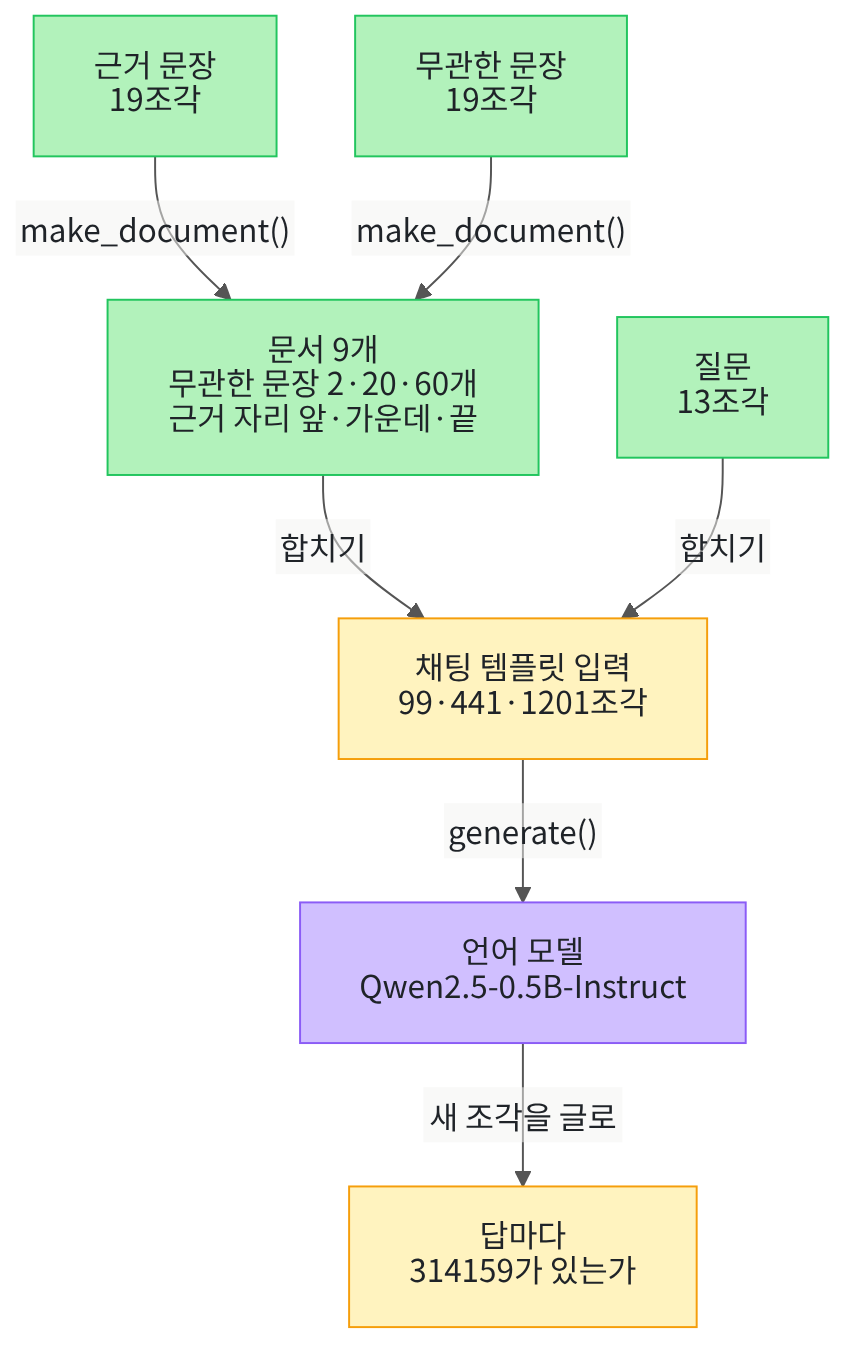

위에서 아래로 읽습니다. 초록 상자는 노트북에서 만든 문장과 문서이고, 노란 상자는 출력으로 확인하는 값입니다.
보라 상자는 내 컴퓨터에서 실행하는 언어 모델입니다. 문서 9개는 무관한 문장 수와 근거의 자리만 다릅니다.

## 1. 준비

이 절은 파일을 읽거나 만들지 않습니다. 준비 셀에서는 transformers 패키지를 불러오고 버전을 확인합니다.

함수 `warnings.filterwarnings()` 줄은 01절처럼 진행 표시 위젯이 없다는 경고 한 줄을 끕니다.
함수 `transformers.logging.set_verbosity_error()`는 04절처럼, 생성 셀에서 나오는 오류가 아닌 안내 두 줄을 끕니다.
어떤 안내인지는 04절 9절 결과 읽기에 적었습니다.

In [1]:
# transformers 패키지를 불러오고, 오류가 아닌 안내 경고를 줄인 뒤 버전을 확인합니다
import warnings

# 진행 표시 위젯이 없다는 경고(TqdmWarning)는 계산과 관계없어 화면에 내지 않습니다
warnings.filterwarnings("ignore", message="IProgress not found")

import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer

# 생성 셀의 안내 두 줄(오류 아님)을 화면에 내지 않습니다
transformers.logging.set_verbosity_error()
print("transformers 버전:", transformers.__version__)

transformers 버전: 4.56.2


**결과 읽기** — 출력 줄은 `transformers 버전: 4.56.2`입니다. 준비물에 적은 기준 버전과 같습니다.

## 2. 모델과 입력 한도

모델은 03·04절과 같은 Qwen2.5-0.5B-Instruct이고, 같은 판 번호로 받습니다.
이번에는 04절의 연습용 한도 512 대신, 모델 설정에 적힌 한도를 그대로 씁니다.

출력 몫은 04절에서 정한 이름으로, 모델이 새로 만들 조각 수의 상한입니다. 이 절의 답은 짧아서 32로 정합니다.
입력 한도는 04절의 식 `입력 한도 = 전체 한도 - 출력 몫`으로 구합니다.
실행 전에 예상합니다. 모델 설정 한도가 04절처럼 32768이면, 입력 한도는 32736일 것입니다.

In [2]:
# 03·04절과 같은 언어 모델과 토큰화기를 받고, 모델 설정 한도에서 출력 몫을 뺀 입력 한도를 구합니다
model_name = "Qwen/Qwen2.5-0.5B-Instruct"
model_revision = "7ae557604adf67be50417f59c2c2f167def9a775"
tokenizer = AutoTokenizer.from_pretrained(model_name, revision=model_revision)
model = AutoModelForCausalLM.from_pretrained(model_name, revision=model_revision)
# 출력 몫은 모델이 새로 만들 조각 수의 상한이고, 입력은 나머지 칸에 넣습니다
output_budget = 32
input_budget = model.config.max_position_embeddings - output_budget
print("모델 설정 max_position_embeddings:", model.config.max_position_embeddings)
print("출력 몫:", output_budget)
print("입력 한도:", input_budget)

모델 설정 max_position_embeddings: 32768
출력 몫: 32
입력 한도: 32736


**결과 읽기** — 출력 줄은 `모델 설정 max_position_embeddings: 32768`, `출력 몫: 32`, `입력 한도: 32736`입니다. 예상과 같습니다.

이 절의 입력이 32736조각 이하이면, 04절처럼 끝을 잘라 낼 일은 없습니다.
이 노트북의 출력은 2026-09-16에 이 모델과 판 번호로 실행한 결과입니다. 실행 환경이나 버전이 바뀌면 답 문장이 달라질 수 있습니다.

## 3. 실험 재료 세 가지

근거 문장은 질문의 답이 들어 있는 문장입니다. 이 절의 근거 문장에는 정답 코드 314159가 들어 있습니다.
무관한 문장은 질문과 관계없이 입력을 길게 만드는 문장입니다. 질문은 확인 코드만 답하라고 요청합니다.

두 문장 끝의 `'\n'`은 줄바꿈 글자입니다. 문장을 이어 붙이면 한 줄에 한 문장씩 놓입니다.
세 글을 01절 메서드 `encode()`로 바꿔 조각 수를 셉니다. 실행 전에 예상합니다. 글자가 더 많은 무관한 문장이 조각도 더 많을 것입니다.

In [3]:
# 근거 문장, 무관한 문장, 질문을 만들고 각각의 토큰 수를 셉니다
fact_sentence = "해바라기 작전의 확인 코드는 314159입니다.\n"
filler_sentence = "주문 조회 화면에는 결제 상태와 배송 상태가 표시됩니다.\n"
question = "해바라기 작전의 확인 코드만 답하세요."
fact_tokens = len(tokenizer.encode(fact_sentence))
filler_tokens = len(tokenizer.encode(filler_sentence))
question_tokens = len(tokenizer.encode(question))
print("근거 문장 토큰 수:", fact_tokens)
print("무관한 문장 토큰 수:", filler_tokens)
print("질문 토큰 수:", question_tokens)

근거 문장 토큰 수: 19
무관한 문장 토큰 수: 19
질문 토큰 수: 13


**결과 읽기** — 출력 줄은 `근거 문장 토큰 수: 19`, `무관한 문장 토큰 수: 19`, `질문 토큰 수: 13`입니다.

예상과 달리 두 문장의 조각 수가 19로 같습니다. 글자 수와 조각 수는 01절에서 본 것처럼 늘 비례하지 않습니다.
두 문장의 조각 수가 같아서, 근거의 자리만 바꾸면 입력의 조각 수는 그대로입니다.

## 4. 근거의 자리를 정해 문서 만들기

문서는 무관한 문장을 여러 번 이은 글 사이에 근거 문장 하나를 끼운 것입니다. 근거의 자리는 근거 앞에 놓인 무관한 문장의 수로 정합니다.
이 수를 이 절에서는 「근거 앞 문장 수」라고 부릅니다. 0이면 근거가 맨 앞이고, 무관한 문장 수와 같으면 맨 끝입니다.

함수는 01·04절처럼 `for`와 `+`로 문장을 잇습니다. 반복 번호 `i`가 근거 앞 문장 수와 같아지면, 그 무관한 문장 앞에 근거 문장을 먼저 붙입니다.
반복이 끝날 때까지 근거를 붙이지 못했다면 근거의 자리가 맨 끝이므로, 반복 뒤에 붙입니다. 이 셀은 함수를 정의만 합니다.

In [4]:
# 무관한 문장 수와 근거 앞 문장 수를 받아, 근거 문장을 그 자리에 끼운 문서 글을 반환하는 함수를 정의합니다
def make_document(filler_count, fact_place):
    document_text = ""
    for i in range(filler_count):
        # 근거 앞에 놓인 무관한 문장이 fact_place개가 된 자리에 근거 문장을 붙입니다
        if i == fact_place:
            document_text = document_text + fact_sentence
        document_text = document_text + filler_sentence
    # 근거 앞 문장 수가 무관한 문장 수와 같으면 근거는 맨 끝입니다
    if fact_place == filler_count:
        document_text = document_text + fact_sentence
    return document_text

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

작은 문서 하나로 함수를 확인합니다. 무관한 문장 2개에 근거 앞 문장 수 1을 주면, 근거가 두 문장 사이에 들어가야 합니다.
문서는 여러 줄이라 라벨을 앞줄에 따로 출력합니다. 실행 전에 예상합니다. 라벨 줄 아래 가운데 줄이 근거 문장일 것입니다.

In [5]:
# 무관한 문장 2개와 근거 앞 문장 수 1로 작은 문서를 만들어, 근거가 들어간 자리를 봅니다
small_document = make_document(2, 1)
print("무관한 문장 2개, 근거 앞 문장 1개인 문서:")
print(small_document)

무관한 문장 2개, 근거 앞 문장 1개인 문서:
주문 조회 화면에는 결제 상태와 배송 상태가 표시됩니다.
해바라기 작전의 확인 코드는 314159입니다.
주문 조회 화면에는 결제 상태와 배송 상태가 표시됩니다.



**결과 읽기** — 라벨 줄 아래 세 줄 가운데 둘째 줄이 `해바라기 작전의 확인 코드는 314159입니다.`입니다. 첫째 줄과 셋째 줄은 무관한 문장입니다.

예상대로 근거 문장이 무관한 문장 두 개 사이에 들어갔습니다. 마지막 빈 줄은 셋째 문장 끝의 줄바꿈 글자 때문에 생겼습니다.

## 5. 아홉 가지 입력과 입력 한도

먼저 입력 글을 만드는 함수를 정의합니다. 이 함수는 문서와 질문을 사용자 메시지 하나에 담습니다.
04절 5절에서 본 것처럼, 시스템 메시지가 없으면 채팅 템플릿이 영어 기본 지시를 넣습니다.

문서 끝에 줄바꿈이 있으므로 질문 앞에 `'\n'`을 하나 더 붙이면, 문서와 질문 사이에 빈 줄이 하나 생깁니다. 이 셀은 함수를 정의만 합니다.

In [6]:
# 문서와 질문을 사용자 메시지 하나에 담고, 채팅 템플릿으로 합친 입력 글을 반환하는 함수를 정의합니다
def make_input_without_system(document_text):
    message_list = [
        {"role": "user", "content": document_text + "\n" + question},
    ]
    return tokenizer.apply_chat_template(message_list, tokenize=False, add_generation_prompt=True)

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

이제 조건 9개를 만듭니다. 무관한 문장 수는 2, 20, 60개입니다. 근거 앞 문장 수는 0(앞), 절반(가운데), 무관한 문장 수(끝)입니다.
절반은 `/`로 나눈 값이 실수라서 Ch 2 01절 함수 `int()`로 정수로 바꿉니다. 예를 들어 `int(20 / 2)`는 10입니다.

조건마다 문서, 입력 글, 토큰 수를 차례로 만듭니다. 조건은 세 값을 담은 목록으로 `conditions`에 모읍니다.
실행 전에 예상합니다. 무관한 문장이 한 개 늘 때마다 19조각씩 늘고, 가장 긴 입력도 입력 한도 32736보다 훨씬 작을 것입니다.

In [7]:
# 무관한 문장 수 3가지와 근거 자리 3가지로 조건 9개를 만들고, 입력 토큰 수가 입력 한도 이하인지 봅니다
conditions = []
print("무관한 문장 수 | 근거 앞 문장 수 | 입력 토큰 수 | 입력 한도 이하")
for filler_count in [2, 20, 60]:
    # 근거의 자리는 맨 앞(0), 가운데(절반), 맨 끝(무관한 문장 수)입니다
    middle_place = int(filler_count / 2)
    for fact_place in [0, middle_place, filler_count]:
        document_text = make_document(filler_count, fact_place)
        input_text = make_input_without_system(document_text)
        token_count = len(tokenizer.encode(input_text))
        conditions.append([filler_count, fact_place, document_text])
        print(filler_count, "|", fact_place, "|", token_count, "|", token_count <= input_budget)

무관한 문장 수 | 근거 앞 문장 수 | 입력 토큰 수 | 입력 한도 이하
2 | 0 | 99 | True
2 | 1 | 99 | True
2 | 2 | 99 | True
20 | 0 | 441 | True
20 | 10 | 441 | True
20 | 20 | 441 | True
60 | 0 | 1201 | True
60 | 30 | 1201 | True
60 | 60 | 1201 | True


**결과 읽기** — 라벨 줄 아래 아홉 줄은 무관한 문장 수마다 세 줄씩입니다. 2개는 `2 | 0 | 99 | True`, 20개는 `20 | 10 | 441 | True`, 60개는 `60 | 30 | 1201 | True`처럼 나옵니다.

같은 무관한 문장 수의 세 줄은 토큰 수가 같습니다. 같은 문장들의 순서만 다르기 때문입니다.
20개에서 60개로 40개 늘자 760조각 늘어, 예상대로 한 문장에 19조각씩입니다. 아홉 줄 모두 마지막 칸이 True라서 한도를 넘은 입력은 없습니다.

## 6. 모델에 묻고 정답 코드 찾기

입력 글을 받아 모델의 답을 반환하는 함수를 정의합니다. 몸통은 04절 9절 셀과 같은 모양입니다.
메서드 `generate()`에 인자 `max_new_tokens`로 출력 몫 32를, 인자 `do_sample=False`로 무작위로 뽑지 않는 설정을 줍니다.

반환된 ID 목록에서 입력 길이만큼을 건너뛴 뒤가 새 조각입니다. 텐서 `input_ids`의 첫 줄 길이가 입력 조각 수입니다.
04절처럼 새 조각을 글로 바꾸면 답 끝에 끝 표시 `<|im_end|>`가 남습니다. 이 셀은 함수를 정의만 합니다.

In [8]:
# 입력 글을 받아, 출력 몫 안에서 모델이 만든 새 조각만 글로 바꿔 반환하는 함수를 정의합니다
def ask_model(input_text):
    input_ids = tokenizer.encode(input_text, return_tensors="pt")
    # do_sample=False는 04절처럼 다음 조각을 무작위로 뽑지 않는 설정입니다
    output_ids = model.generate(input_ids=input_ids, max_new_tokens=output_budget, do_sample=False)
    all_ids = output_ids[0].tolist()
    # 입력 조각 수만큼 건너뛴 뒤가 새 조각입니다
    input_length = len(input_ids[0])
    new_ids = all_ids[input_length:len(all_ids)]
    return tokenizer.decode(new_ids)

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

조건 9개를 차례로 모델에 넣습니다. 시스템 메시지 없는 입력 모양은 결과를 보기 전에 정해 둔 모양입니다. 한 조건은 목록 세 칸이라, Ch 2 03절 풀어 담기로 `for` 줄에서 세 이름에 나눠 담습니다.
답에 정답 코드 `"314159"`가 들어 있는지는 연산자 `in`으로 봅니다. 이 판정은 코드를 찾았는지만 보고, 문장이 자연스러운지는 보지 않습니다.

답 안의 줄바꿈은 메서드 `replace()`로 빈칸으로 바꿔 출력해, 조건 하나를 한 줄에 봅니다. 판정은 바꾸기 전의 답으로 합니다.
나중에 한 번 더 실행해 비교하려고 답을 `answers`에 모읍니다. 실행 전에 예상합니다. 입력이 한도 안이니 아홉 조건 모두 314159를 답할 것입니다.

In [9]:
# 아홉 가지 입력을 차례로 모델에 넣고, 답에 정답 코드 314159가 들어 있는지 봅니다
answers = []
print("무관한 문장 수 | 근거 앞 문장 수 | 314159 있음 | 답")
for filler_count, fact_place, document_text in conditions:
    input_text = make_input_without_system(document_text)
    answer = ask_model(input_text)
    answers.append(answer)
    found = "314159" in answer
    # 답 안의 줄바꿈은 빈칸으로 바꿔, 조건 하나를 한 줄에 출력합니다
    print(filler_count, "|", fact_place, "|", found, "|", answer.replace("\n", " "))

무관한 문장 수 | 근거 앞 문장 수 | 314159 있음 | 답


2 | 0 | True | 314159<|im_end|>


2 | 1 | False | 결제 상태: 완료 배송 상태: 완료<|im_end|>


2 | 2 | False | 결제 상태: 완료 배송 상태: 완료<|im_end|>


20 | 0 | True | 해바라기 작전의 확인 코드는 314159입니다.<|im_end|>


20 | 10 | False | 주문 조회 화면에는 결제 상태와 배송 상태가 표시되지 않습니다.<|im_end|>


20 | 20 | True | 해바라기 작전의 확인 코드는 314159입니다.<|im_end|>


60 | 0 | True | 314159<|im_end|>


60 | 30 | False | 주문 조회 화면에는 결제 상태와 배송 상태가 표시됩니다.<|im_end|>


60 | 60 | True | 해바라기 작전의 확인 코드는 314159입니다.<|im_end|>


**결과 읽기** — 라벨 줄 아래 앞 자리 세 줄 `2 | 0 | True`, `20 | 0 | True`, `60 | 0 | True`는 모두 맞았습니다. 가운데 자리 세 줄 `2 | 1 | False`, `20 | 10 | False`, `60 | 30 | False`는 모두 틀렸습니다.

끝 자리는 `2 | 2 | False`만 틀리고, `20 | 20 | True`와 `60 | 60 | True`는 맞았습니다. 예상과 달리 한도 안의 입력에서도 9개 가운데 4개가 틀렸습니다.
틀린 답은 근거 대신 무관한 문장의 내용을 썼습니다. 무관한 문장 2개 조건은 `결제 상태: 완료 배송 상태: 완료`처럼 문서에 없는 상태를 지어냈습니다.

60개 가운데 조건의 답은 무관한 문장을 그대로 옮긴 `주문 조회 화면에는 결제 상태와 배송 상태가 표시됩니다.`입니다.
정답 수는 무관한 문장 2개일 때 1개, 20개와 60개일 때 2개씩이었습니다. 입력이 길어져도 정답 수는 줄지 않았습니다.

## 7. 같은 입력으로 한 번 더

6절의 답이 우연히 나온 것인지 확인합니다. 같은 입력 9개로 한 번 더 실행하고, 6절의 답과 글자까지 같은지 셉니다.
6절에서 모은 `answers`의 순서는 `conditions`의 순서와 같습니다. 그래서 조건 번호 `number`를 0부터 하나씩 늘리며 같은 자리의 답과 비교합니다.

실행 전에 예상합니다. 무작위로 뽑지 않았으니 9개 모두 같은 답일 것입니다.

In [10]:
# 시스템 메시지 없이 넣은 아홉 입력을 한 번 더 실행해, 6절의 답과 같은지 셉니다
same_count = 0
number = 0
for filler_count, fact_place, document_text in conditions:
    input_text = make_input_without_system(document_text)
    answer = ask_model(input_text)
    # 같은 조건 번호에 모아 둔 6절의 답과 글자까지 같은지 비교합니다
    if answer == answers[number]:
        same_count = same_count + 1
    number = number + 1
print("같은 답 수:", same_count, "/", len(conditions))

같은 답 수: 9 / 9


**결과 읽기** — 출력 줄은 `같은 답 수: 9 / 9`입니다. 예상대로 9개 조건 모두 6절과 같은 답이 나왔습니다.

같은 입력은 같은 답을 냈으므로, 6절의 False는 한 번 우연히 나온 결과가 아닙니다.
다만 두 번 모두 틀렸다고 가운데 자리의 실패율이 100%라는 뜻은 아닙니다. 무작위를 끈 같은 계산을 두 번 한 것이지, 서로 다른 시도를 두 번 한 것이 아닙니다.

## 8. 값 바꿔 보기 — 04절 시스템 지시 넣기

바꾸는 값은 입력의 모양 하나입니다. 04절에서 쓴 시스템 지시 「주어진 문서 범위에서만 답하세요.」를 시스템 메시지로 넣습니다.
문서, 질문, 조건 9개, 모델, 출력 몫은 그대로입니다. 먼저 04절 `make_input_text()`와 같은 모양의 함수를 새 이름으로 정의합니다. 이 셀은 함수를 정의만 합니다.

In [11]:
# 04절 시스템 지시를 시스템 메시지로 넣고, 문서와 질문은 사용자 메시지에 담는 함수를 정의합니다
system_text = "주어진 문서 범위에서만 답하세요."


def make_input_with_system(document_text):
    message_list = [
        {"role": "system", "content": system_text},
        {"role": "user", "content": document_text + "\n" + question},
    ]
    return tokenizer.apply_chat_template(message_list, tokenize=False, add_generation_prompt=True)

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

4절의 작은 문서로 두 함수의 입력 글을 만들어 비교합니다. 영어 기본 지시의 첫 글자 `"You are Qwen"`이 들어 있는지와, 우리 시스템 지시가 들어 있는지를 `in`으로 봅니다.
실행 전에 예상합니다. 시스템 메시지를 넣으면 영어 기본 지시는 들어가지 않을 것입니다.

In [12]:
# 작은 문서로 두 함수의 입력 글을 만들어, 어느 지시가 들어 있는지 비교합니다
without_system_text = make_input_without_system(small_document)
with_system_text = make_input_with_system(small_document)
print("입력 모양 | 영어 기본 지시 | 04절 시스템 지시")
print("시스템 메시지 없음 |", "You are Qwen" in without_system_text, "|", system_text in without_system_text)
print("04절 시스템 지시 |", "You are Qwen" in with_system_text, "|", system_text in with_system_text)

입력 모양 | 영어 기본 지시 | 04절 시스템 지시
시스템 메시지 없음 | True | False
04절 시스템 지시 | False | True


**결과 읽기** — 라벨 줄 아래 두 줄은 `시스템 메시지 없음 | True | False`와 `04절 시스템 지시 | False | True`입니다.

예상대로 두 입력은 지시 한 가지만 다릅니다. 시스템 메시지가 없으면 영어 기본 지시가, 있으면 우리 지시가 들어갑니다.
이제 이 함수로 조건 9개를 다시 실행합니다. 실행 전에 예상합니다. 지시만 바꿨으니 6절처럼 가운데 자리가 틀릴 것입니다.

In [13]:
# 04절 시스템 지시를 넣은 입력으로 같은 아홉 조건을 실행해, 답에 314159가 있는지 봅니다
print("무관한 문장 수 | 근거 앞 문장 수 | 314159 있음 | 답")
for filler_count, fact_place, document_text in conditions:
    input_text = make_input_with_system(document_text)
    answer = ask_model(input_text)
    found = "314159" in answer
    print(filler_count, "|", fact_place, "|", found, "|", answer.replace("\n", " "))

무관한 문장 수 | 근거 앞 문장 수 | 314159 있음 | 답


2 | 0 | True | 314159<|im_end|>


2 | 1 | True | 314159<|im_end|>


2 | 2 | True | 314159<|im_end|>


20 | 0 | True | 314159<|im_end|>


20 | 10 | True | 314159<|im_end|>


20 | 20 | True | 314159<|im_end|>


60 | 0 | True | 314159<|im_end|>


60 | 30 | True | 314159<|im_end|>


60 | 60 | True | 314159<|im_end|>


**결과 읽기** — 라벨 줄 아래 아홉 줄이 모두 True입니다. 가운데 자리 세 줄도 `2 | 1 | True | 314159<|im_end|>`처럼 코드만 답했습니다.

예상과 달리 6절에서 틀린 4개 조건이 모두 맞았습니다. 근거의 자리에 따른 차이가 시스템 지시 한 문장으로 사라졌습니다.
그래서 6절의 결과를 「이 모델은 가운데 근거를 쓰지 못한다」로 넓혀 말하지 않습니다. 이번에 본 것은 모델 하나, 입력 모양 두 가지, 조건 9개입니다.

## 정리

- 근거의 자리와 무관한 문장 수만 바꾼 입력 9개는 모두 입력 한도 32736 안이었습니다. 가장 긴 입력은 1201조각이었습니다.
- 사용자 메시지 하나로 넣자 가운데 자리 세 조건과 끝 자리 한 조건이 틀렸습니다. 다시 실행해도 9개 답이 같았고, 입력이 길어져도 정답 수는 줄지 않았습니다.
- 04절 시스템 지시를 넣자 9개 조건이 모두 맞았습니다. 자리에 따른 차이는 입력 모양에 따라 나타나거나 사라졌습니다.

입력이 한도 안에 있어도 모델이 모든 정보를 똑같이 쓴다고 가정하지 않고, 내 입력 모양으로 직접 확인합니다.
다음 06절에서는 이 절에서 꺼 둔 무작위 뽑기를 켭니다. 그리고 temperature를 바꿔 같은 입력의 답이 어떻게 달라지는지 봅니다.